In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
con = duckdb.connect("tracking_analysis.duckdb")

# 1. All systems
con.execute("""
CREATE OR REPLACE TABLE UID_STATS AS
SELECT uid, AVG(size) AS mean_size, MAX(size) AS max_size
FROM read_parquet('track_amazon_lluc/tracking_table/monthly/*.parquet')
WHERE uid IS NOT NULL
  AND size IS NOT NULL
  AND isfinite(size)
GROUP BY uid
""")

# 2. Systems with duration >= 60 minutes
con.execute("""
CREATE OR REPLACE TABLE UID_STATS_60 AS
SELECT uid, AVG(size) AS mean_size, MAX(size) AS max_size
FROM read_parquet('tracking_table_60min.parquet')
WHERE uid IS NOT NULL
  AND size IS NOT NULL
  AND isfinite(size)
GROUP BY uid
""")

# 3. Systems with duration >= 120 minutes
con.execute("""
CREATE OR REPLACE TABLE UID_STATS_120 AS
SELECT uid, AVG(size) AS mean_size, MAX(size) AS max_size
FROM read_parquet('tracking_table_120min.parquet')
WHERE uid IS NOT NULL
  AND size IS NOT NULL
  AND isfinite(size)
GROUP BY uid
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [7]:
# Load the three tables from DuckDB into pandas DataFrames
df_all = con.execute("SELECT * FROM UID_STATS").df()
df_60min = con.execute("SELECT * FROM UID_STATS_60").df()
df_120min = con.execute("SELECT * FROM UID_STATS_120").df()

table_names = {
    "All systems": "UID_STATS",
    "Duration >= 60 min": "UID_STATS_60",
    "Duration >= 120 min": "UID_STATS_120"
}

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

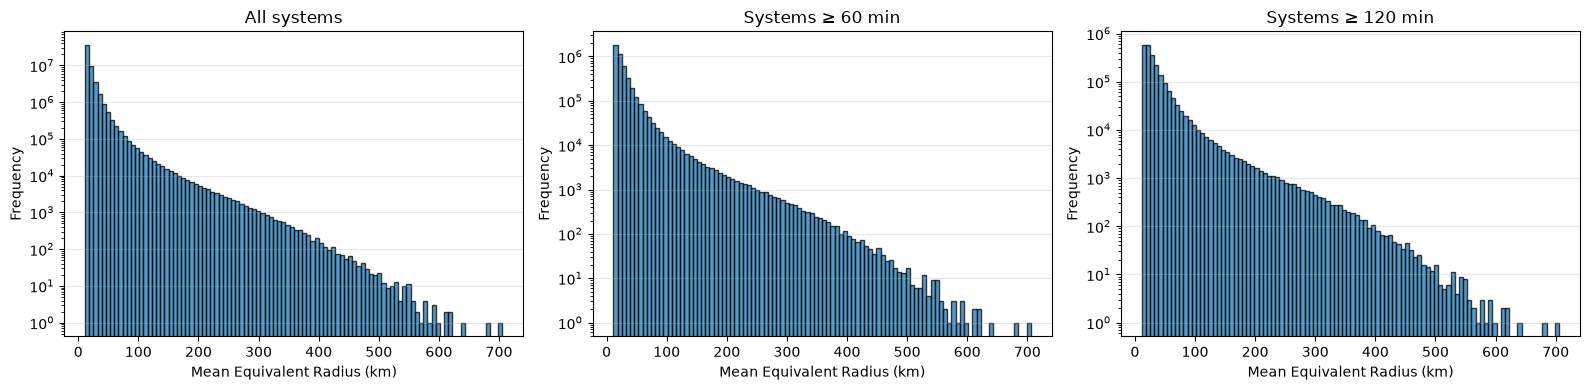

In [14]:
# DataFrames
datasets = {
    "All systems": np.sqrt((df_all["mean_size"].dropna() * 100) / np.pi),
    "Systems ≥ 60 min": np.sqrt((df_60min["mean_size"].dropna() * 100) / np.pi),
    "Systems ≥ 120 min": np.sqrt((df_120min["mean_size"].dropna() * 100) / np.pi)
}

# Use the same bin edges for all three distributions
n_bins = 100

min_val = min(data.min() for data in datasets.values())
max_val = max(data.max() for data in datasets.values())

bins = np.linspace(min_val, max_val, n_bins + 1)
bin_width = bins[1] - bins[0]

# Create three panels
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, (title, data) in zip(axes, datasets.items()):
    frequency, bin_edges = np.histogram(data, bins=bins)
    centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax.bar(centers, frequency, width=bin_width, edgecolor="black", alpha=0.75)
    ax.set_xlabel("Mean Equivalent Radius (km)", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.set_title(title, fontsize=12)
    ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

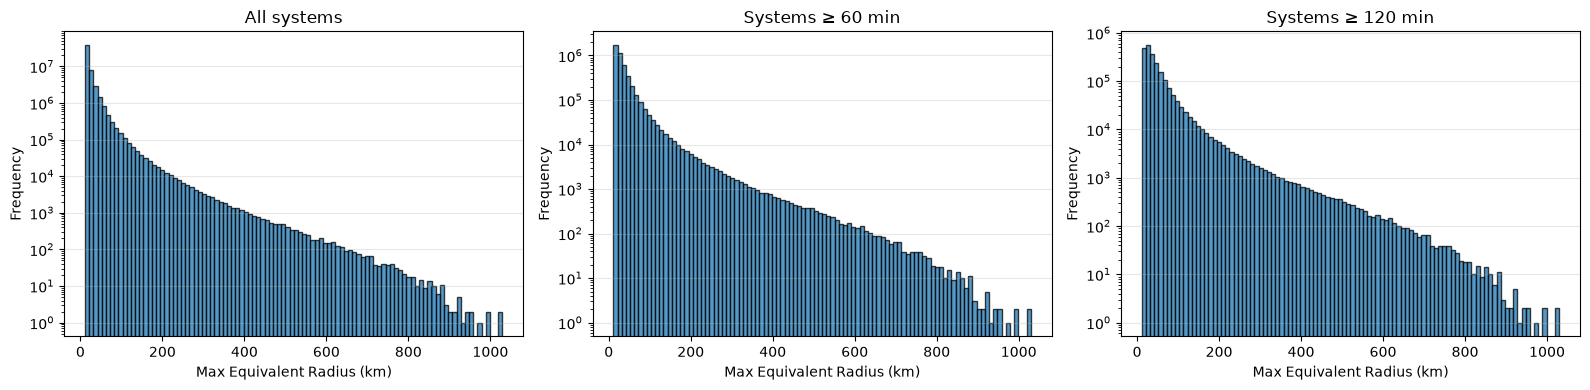

In [15]:
# DataFrames
datasets = {
    "All systems": np.sqrt((df_all["max_size"].dropna() * 100) / np.pi),
    "Systems ≥ 60 min": np.sqrt((df_60min["max_size"].dropna() * 100) / np.pi),
    "Systems ≥ 120 min": np.sqrt((df_120min["max_size"].dropna() * 100) / np.pi)
}

# Use the same bin edges for all three distributions
n_bins = 100

min_val = min(data.min() for data in datasets.values())
max_val = max(data.max() for data in datasets.values())

bins = np.linspace(min_val, max_val, n_bins + 1)
bin_width = bins[1] - bins[0]

# Create three panels
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, (title, data) in zip(axes, datasets.items()):
    frequency, bin_edges = np.histogram(data, bins=bins)
    centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax.bar(centers, frequency, width=bin_width, edgecolor="black", alpha=0.75)
    ax.set_xlabel("Max Equivalent Radius (km)", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.set_title(title, fontsize=12)
    ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()